# Problema 1 — Inciso (b): calibración de probabilidades

Esta libreta parte de los resultados de `03_modelos`:

- `resultados/03_resumen_modelos.csv`: AUC de validación cruzada y de prueba
  de cada modelo.
- `resultados/03_probabilidades_test.csv`: probabilidades de prueba de ambos
  modelos, más el objetivo y `SEX` (solo para auditoría).

Reglas que respeta:

- El **mejor modelo** se elige por AUC de validación cruzada, no por AUC de
  prueba.
- `SEX` **no** es variable de entrada: solo se usa para separar la auditoría
  por grupo.
- La calibración se ajusta **solo con el 70% de entrenamiento**, con
  `CalibratedClassifierCV(cv=5)` dentro de ese 70%.
- Se usa **un único calibrador global**. No se calibra por grupo: esa
  decisión se registra en la bitácora (Decisión 4).
- El 30% de prueba se usa para evaluar y comparar, no para ajustar el
  calibrador ni para elegir el método.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo.

    La raíz se reconoce porque contiene `common.py` y la carpeta `problema-1/`.
    Así la libreta funciona igual si se abre desde la raíz o desde
    `problema-1/`, y también cuando la ejecuta `nbconvert`.
    """
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-1").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-1" if (_RAIZ / "problema-1").is_dir() else _RAIZ

# Permite importar common.py (raíz) y los módulos de problema-1/.
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import SEED
from data import TARGET, cargar_dataframe
import evidencia_datos as ev
import modelos as mo

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

ETIQUETAS_METODO = {
    "sin_calibrar": "Sin calibrar",
    "sigmoid": "Sigmoide",
    "isotonic": "Isotónico",
}
COLORES = {
    "sin_calibrar": "tab:blue",
    "sigmoid": "tab:orange",
    "isotonic": "tab:green",
}

print(f"SEED = {SEED}")
print(f"Variable objetivo = '{TARGET}'")
print(f"Directorio de resultados = {RESULTADOS}")

SEED = 223210350
Variable objetivo = 'default payment next month'
Directorio de resultados = /home/tito/repos/RDP/Examen_1_RDP/resultados


## 1. Carga de resultados y elección del mejor modelo

Se cargan el resumen de `03_modelos` y las probabilidades de prueba. El
mejor modelo se elige con `auc_cv_medio`, que es el AUC medio de las 5
particiones de validación cruzada del 70%. La columna `auc_test` se muestra
solo como reporte y **no** participa en la elección.

Después se reconstruye el `Pipeline` con los hiperparámetros guardados y se
comprueba que sus probabilidades coincidan con las que guardó `03_modelos`.
Esa verificación evita calibrar un modelo distinto al que se evaluó.

In [2]:
ruta_resumen = RESULTADOS / "03_resumen_modelos.csv"
ruta_probabilidades = RESULTADOS / "03_probabilidades_test.csv"
ruta_mejor = RESULTADOS / "03_mejor_modelo.csv"

for ruta in (ruta_resumen, ruta_probabilidades):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero 03_modelos.ipynb."
        )

resumen = pd.read_csv(ruta_resumen)
tabla_probabilidades = pd.read_csv(ruta_probabilidades)

columnas_resumen = {
    "modelo_id",
    "modelo",
    "variante_raros_id",
    "variante_pay_id",
    "hiperparametros",
    "auc_cv_medio",
    "auc_cv_std",
    "auc_test",
    "mejor_por_auc_cv",
}
if not columnas_resumen.issubset(resumen.columns):
    raise ValueError(
        f"{ruta_resumen} no tiene las columnas esperadas: "
        f"{sorted(columnas_resumen - set(resumen.columns))} faltantes."
    )

# La elección se hace estrictamente por AUC de validación cruzada.
mejor = resumen.loc[resumen["auc_cv_medio"].idxmax()].copy()
if mejor["mejor_por_auc_cv"] != "sí":
    raise ValueError(
        "La fila con mayor AUC de CV no está marcada como mejor en "
        "03_resumen_modelos.csv. Revisa 03_modelos antes de continuar."
    )

if ruta_mejor.exists():
    mejor_guardado = pd.read_csv(ruta_mejor).iloc[0]
    if mejor_guardado["modelo_id"] != mejor["modelo_id"]:
        raise ValueError(
            "03_mejor_modelo.csv y 03_resumen_modelos.csv no coinciden en el "
            "modelo elegido."
        )

tabla_eleccion = resumen[
    [
        "modelo_id",
        "modelo",
        "auc_cv_medio",
        "auc_cv_std",
        "auc_test",
        "mejor_por_auc_cv",
    ]
].sort_values("auc_cv_medio", ascending=False)
display(tabla_eleccion.round(6))

print(
    "Mejor modelo por AUC de CV: "
    f"{mejor['modelo']} "
    f"(AUC CV = {mejor['auc_cv_medio']:.6f} ± {mejor['auc_cv_std']:.6f})."
)
print(
    "AUC de prueba de ese modelo: "
    f"{mejor['auc_test']:.6f} (solo reporte; no se usa para elegir)."
)

,modelo_id,modelo,auc_cv_medio,auc_cv_std,auc_test,mejor_por_auc_cv
1,hist_gb,HistGradientBoostingClassifier,0.781596,0.005092,0.777742,sí
0,logistica,Regresión logística con escalado,0.766918,0.003044,0.758502,no


Mejor modelo por AUC de CV: HistGradientBoostingClassifier (AUC CV = 0.781596 ± 0.005092).
AUC de prueba de ese modelo: 0.777742 (solo reporte; no se usa para elegir).


La tabla confirma que `HistGradientBoostingClassifier` tiene el mayor AUC
medio de validación cruzada (`0.781596` frente a `0.766918` de la regresión
logística). Por eso se calibra ese modelo. El AUC de prueba (`0.777742`) se
muestra solo como referencia: si se hubiera usado para elegir, se habría
filtrado información del conjunto de prueba a la selección.

In [3]:
# Cargamos el dataset y el split para reconstruir el modelo y para tener
# disponibles las columnas de entrada y el 70% de entrenamiento.
df = cargar_dataframe()
columnas_pay = mo.obtener_columnas_pay(df)

ruta_split = RESULTADOS / "split_indices.csv"
if not ruta_split.exists():
    raise FileNotFoundError(
        f"No existe {ruta_split}. Ejecuta primero 02_decisiones_datos.ipynb."
    )

idx_train, idx_test = ev.cargar_indices(ruta_split, df, TARGET)
idx_train_esperado, idx_test_esperado = ev.dividir_estratificado(
    df, TARGET, test_size=0.30, seed=SEED
)
if not (
    np.array_equal(idx_train, idx_train_esperado)
    and np.array_equal(idx_test, idx_test_esperado)
):
    raise ValueError(
        "El split guardado no coincide con el split reproducible de SEED. "
        "Revisa resultados/split_indices.csv antes de continuar."
    )

columnas_x = mo.columnas_entrada(df, TARGET, incluir_sexo=mo.INCLUIR_SEXO)
if "SEX" in columnas_x:
    raise ValueError("SEX no debe estar en las columnas de entrada del modelo.")

X_train = df.iloc[idx_train][columnas_x].reset_index(drop=True)
y_train = df.iloc[idx_train][TARGET].reset_index(drop=True)
X_test = df.iloc[idx_test][columnas_x].reset_index(drop=True)

# Validamos que el archivo de probabilidades esté alineado con el split.
if not np.array_equal(tabla_probabilidades["indice"].to_numpy(), idx_test):
    raise ValueError(
        "Los índices de 03_probabilidades_test.csv no coinciden con el split."
    )
if not np.array_equal(
    tabla_probabilidades["objetivo"].to_numpy(),
    df.iloc[idx_test][TARGET].to_numpy(),
):
    raise ValueError(
        "La columna 'objetivo' de 03_probabilidades_test.csv no coincide con "
        "el dataset."
    )
if not np.array_equal(
    tabla_probabilidades["SEX"].to_numpy(),
    df.iloc[idx_test]["SEX"].to_numpy(),
):
    raise ValueError(
        "La columna 'SEX' de 03_probabilidades_test.csv no coincide con el "
        "dataset."
    )

y_test = tabla_probabilidades["objetivo"].to_numpy()
sexo_test = tabla_probabilidades["SEX"].to_numpy()
prob_sin_calibrar = tabla_probabilidades[f"prob_{mejor['modelo_id']}"].to_numpy()

# Reconstruimos exactamente el Pipeline del mejor modelo y verificamos que
# reproduzca las probabilidades guardadas por 03_modelos.
pipeline_mejor = mo.construir_pipeline_desde_mejor(
    mejor, columnas_pay, seed=SEED
)
pipeline_mejor.fit(X_train, y_train)
prob_reconstruida = pipeline_mejor.predict_proba(X_test)[:, 1]
diferencia_reconstruccion = float(
    np.max(np.abs(prob_reconstruida - prob_sin_calibrar))
)
if diferencia_reconstruccion > 1e-7:
    raise ValueError(
        "El modelo reconstruido no reproduce las probabilidades de "
        f"03_modelos (diferencia máxima = {diferencia_reconstruccion:.2e})."
    )

print(f"Filas de entrenamiento: {len(X_train)}")
print(f"Filas de prueba: {len(X_test)}")
print(f"Columnas de entrada ({len(columnas_x)}): {columnas_x}")
print(f"¿SEX está en las columnas de entrada? {'SEX' in columnas_x}")
print(
    "Diferencia máxima entre las probabilidades guardadas y las "
    f"reconstruidas: {diferencia_reconstruccion:.2e}"
)

Filas de entrenamiento: 21000
Filas de prueba: 9000
Columnas de entrada (22): ['LIMIT_BAL', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
¿SEX está en las columnas de entrada? False
Diferencia máxima entre las probabilidades guardadas y las reconstruidas: 5.00e-09


La reconstrucción coincide con las probabilidades guardadas (diferencia
máxima del orden de `5e-9`, muy por debajo de la tolerancia `1e-7`). Esto
confirma que el `Pipeline`, los hiperparámetros y el split son los mismos que
usó `03_modelos`. `SEX` sigue fuera de las 22 columnas de entrada y solo se
usará para separar la auditoría por grupo.

## 2. Funciones de calibración y tabla por grupo

Definimos aquí las funciones que se usan en todas las tablas y gráficas:

- **ECE**: error medio de calibración con 10 bins por cuantiles. Es el
  promedio de `|probabilidad media predicha − tasa real|`, ponderado por el
  tamaño de cada bin. Un ECE de `0.01` equivale a 1 punto porcentual.
- **Métricas**: AUC, Brier, log-loss, ECE, puntaje promedio, tasa real y
  diferencia.
- **Tabla por grupo**: `n`, puntaje promedio, tasa real de incumplimiento,
  diferencia `E[S|G=g] − p_g` y ECE de cada grupo.
- **Curva de calibración**: `calibration_curve` con `n_bins=10` y
  `strategy="quantile"`, como pide el inciso.

In [4]:
def ece_calibracion(
    y: np.ndarray, probabilidad: np.ndarray, n_bins: int = 10
) -> float:
    """Calcula el Expected Calibration Error con bins por cuantiles.

    ``y`` son las etiquetas reales y ``probabilidad`` las probabilidades
    predichas. Cada bin aporta su tamaño relativo multiplicado por la
    diferencia absoluta entre la probabilidad media y la tasa real del bin.
    """
    y = np.asarray(y, dtype=float)
    probabilidad = np.asarray(probabilidad, dtype=float)
    bins = pd.qcut(probabilidad, q=n_bins, labels=False, duplicates="drop")
    bins = np.asarray(bins)
    total = 0.0
    for valor_bin in np.unique(bins):
        mascara = bins == valor_bin
        if not mascara.any():
            continue
        total += mascara.mean() * abs(
            probabilidad[mascara].mean() - y[mascara].mean()
        )
    return float(total)


def metricas_calibracion(
    y: np.ndarray, probabilidad: np.ndarray, n_bins: int = 10
) -> dict[str, float]:
    """Resume AUC, Brier, log-loss, ECE y medias de una probabilidad."""
    y = np.asarray(y, dtype=float)
    probabilidad = np.asarray(probabilidad, dtype=float)
    return {
        "auc": float(roc_auc_score(y, probabilidad)),
        "brier": float(brier_score_loss(y, probabilidad)),
        "log_loss": float(log_loss(y, probabilidad)),
        "ece": ece_calibracion(y, probabilidad, n_bins=n_bins),
        "puntaje_promedio": float(probabilidad.mean()),
        "tasa_real": float(y.mean()),
        "diferencia": float(probabilidad.mean() - y.mean()),
    }


def tabla_por_grupo(
    y: np.ndarray,
    probabilidad: np.ndarray,
    sexo: np.ndarray,
    n_bins: int = 10,
) -> pd.DataFrame:
    """Tabla de auditoría por grupo: n, puntaje, tasa real y diferencia.

    ``E[S|G=g]`` se estima con el puntaje promedio del grupo y ``p_g`` con la
    tasa real de incumplimiento del grupo. La columna ``diferencia`` verifica
    numéricamente que ambos valores sean cercanos.
    """
    y = np.asarray(y, dtype=float)
    probabilidad = np.asarray(probabilidad, dtype=float)
    sexo = np.asarray(sexo)
    grupos = [
        ("Todos", np.ones(len(y), dtype=bool)),
        ("Hombres (SEX=1)", sexo == 1),
        ("Mujeres (SEX=2)", sexo == 2),
    ]
    filas = []
    for etiqueta, mascara in grupos:
        y_grupo = y[mascara]
        prob_grupo = probabilidad[mascara]
        filas.append(
            {
                "grupo": etiqueta,
                "n": int(mascara.sum()),
                "puntaje_promedio": float(prob_grupo.mean()),
                "tasa_real_incumplimiento": float(y_grupo.mean()),
                "diferencia": float(
                    prob_grupo.mean() - y_grupo.mean()
                ),
                "ece": ece_calibracion(
                    y_grupo, prob_grupo, n_bins=n_bins
                ),
            }
        )
    tabla = pd.DataFrame(filas)
    tabla["diferencia_pp"] = 100.0 * tabla["diferencia"]
    return tabla


def graficar_curva(
    ax: plt.Axes,
    y: np.ndarray,
    probabilidad: np.ndarray,
    etiqueta: str,
    color: str,
    n_bins: int = 10,
) -> None:
    """Dibuja una curva de calibración con la diagonal de referencia."""
    prob_true, prob_pred = calibration_curve(
        y,
        probabilidad,
        n_bins=n_bins,
        strategy="quantile",
    )
    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        markersize=4,
        linewidth=1.6,
        color=color,
        label=etiqueta,
    )
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.0,
        color="0.45",
        label="Calibración perfecta",
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Probabilidad media predicha")
    ax.set_ylabel("Fracción real de incumplimiento")
    ax.legend(loc="upper left", fontsize=8)

## 3. Evaluación antes de calibrar

Primero se revisa el modelo tal como salió de `03_modelos`. La tabla por
grupo permite verificar si el puntaje promedio de cada grupo se parece a su
tasa real de incumplimiento. Después se dibuja la curva de calibración global
y las curvas por grupo.

In [5]:
tabla_antes = tabla_por_grupo(y_test, prob_sin_calibrar, sexo_test)
display(tabla_antes.round(6))

ruta_grupos_antes = RESULTADOS / "04_tabla_grupos_antes.csv"
tabla_antes.to_csv(ruta_grupos_antes, index=False, float_format="%.8f")

metricas_antes = metricas_calibracion(y_test, prob_sin_calibrar)
print(
    "Antes de calibrar: "
    f"AUC = {metricas_antes['auc']:.6f}, "
    f"Brier = {metricas_antes['brier']:.6f}, "
    f"log-loss = {metricas_antes['log_loss']:.6f}, "
    f"ECE = {metricas_antes['ece']:.6f}."
)
print(f"Tabla guardada en: {ruta_grupos_antes}")

,grupo,n,puntaje_promedio,tasa_real_incumplimiento,diferencia,ece,diferencia_pp
0,Todos,9000,0.221655,0.221222,0.000433,0.017198,0.043304
1,Hombres (SEX=1),3584,0.231632,0.232980,-0.001348,0.015127,-0.134773
2,Mujeres (SEX=2),5416,0.215053,0.213442,0.001611,0.020334,0.161145


Antes de calibrar: AUC = 0.777742, Brier = 0.135678, log-loss = 0.431908, ECE = 0.017198.
Tabla guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_tabla_grupos_antes.csv


En la tabla anterior, `E[S|G=g]` es el puntaje promedio y `p_g` es la tasa
real. Las diferencias son pequeñas en los tres grupos: `+0.000433` en todos,
`−0.001348` en hombres y `+0.001611` en mujeres. Es decir, en promedio el
modelo acierta la tasa de cada grupo. Sin embargo, el ECE global es `0.017198`
(1.72 puntos porcentuales), y el de mujeres es `0.020334` (2.03 pp). Eso
indica que, aunque las medias coincidan, hay desviaciones locales a lo largo
de la escala de probabilidad. Con el criterio práctico de ECE global mayor a
`0.01`, el modelo **no está suficientemente calibrado** y se justifica
calibrarlo.

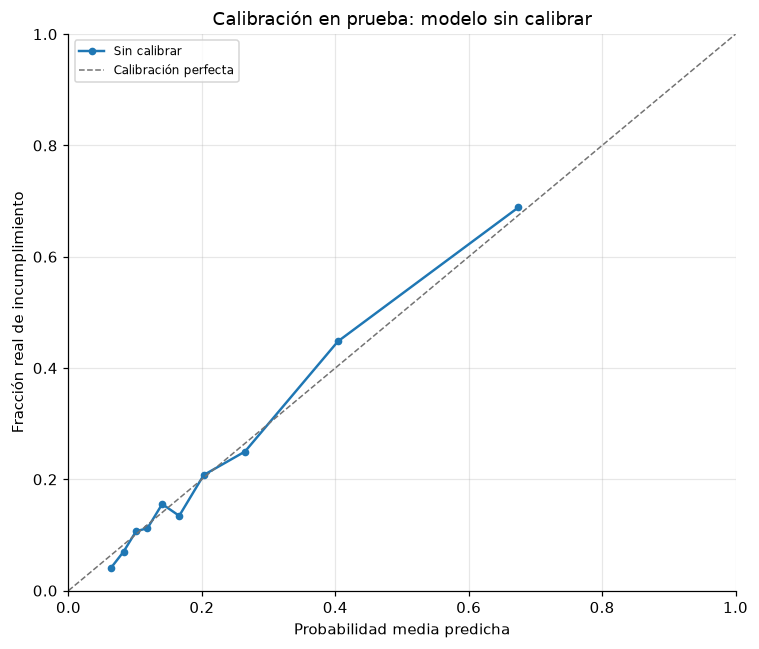

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
graficar_curva(
    ax,
    y_test,
    prob_sin_calibrar,
    "Sin calibrar",
    COLORES["sin_calibrar"],
)
ax.set_title("Calibración en prueba: modelo sin calibrar")
fig.tight_layout()
ruta_figura_global_antes = RESULTADOS / "04_calibracion_global_antes.png"
fig.savefig(ruta_figura_global_antes, bbox_inches="tight")
plt.show()

La curva sin calibrar se acerca a la diagonal, pero no la sigue de forma
exacta: en la zona baja predice de más (por ejemplo, el primer bin predice
`0.0631` y la tasa real es `0.0400`) y en la zona media hay un tramo donde
predice de menos (el bin de `0.1660` tiene tasa real `0.1344`). Esa es la
descalibración local que resume el ECE. La figura se guardó en
`resultados/04_calibracion_global_antes.png`.

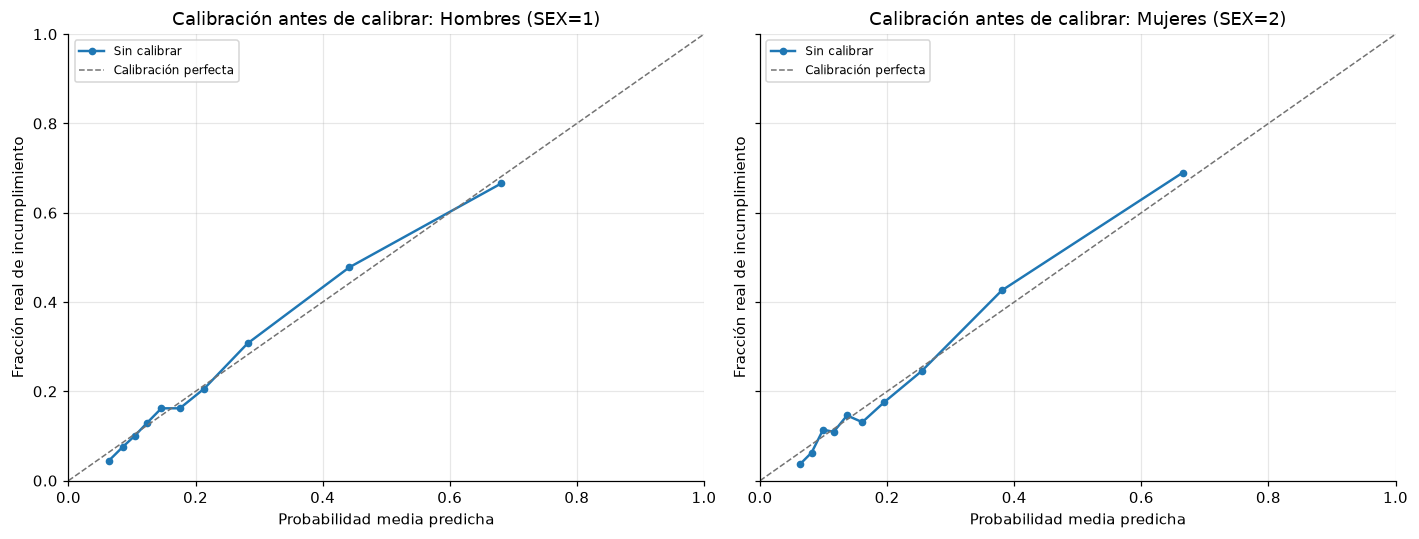

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (sexo_valor, nombre) in zip(
    axes,
    [(1, "Hombres (SEX=1)"), (2, "Mujeres (SEX=2)")],
):
    mascara = sexo_test == sexo_valor
    graficar_curva(
        ax,
        y_test[mascara],
        prob_sin_calibrar[mascara],
        "Sin calibrar",
        COLORES["sin_calibrar"],
    )
    ax.set_title(f"Calibración antes de calibrar: {nombre}")
fig.tight_layout()
ruta_figura_grupos_antes = RESULTADOS / "04_calibracion_grupos_antes.png"
fig.savefig(ruta_figura_grupos_antes, bbox_inches="tight")
plt.show()

Las curvas por grupo muestran que la descalibración no es idéntica en hombres
y mujeres. En mujeres el ECE es `0.020334` y la curva se separa más de la
diagonal en varios bins; en hombres el ECE es `0.015127`. La diferencia de
medias sigue siendo pequeña, pero la forma de la curva sí cambia. Esta figura
se guardó en `resultados/04_calibracion_grupos_antes.png`.

## 4. Comparación sigmoide contra isotónico con validación cruzada anidada

El método de calibración se elige **sin mirar el 30% de prueba**. Para eso se
hace una validación cruzada anidada dentro del 70%:

- 5 particiones externas estratificadas sobre el 70%.
- En cada partición, se ajusta `CalibratedClassifierCV(cv=5)` con el 80%
  interno y se predice el 20% externo.
- Se comparan sigmoide e isotónico (y el modelo sin calibrar como
  referencia) con las predicciones fuera de muestra del 70%.

El criterio principal es **log-loss** (menor es mejor), porque la calibración
busca probabilidades bien calibradas, no reordenar los casos. El Brier y el
AUC se reportan como apoyo.

In [8]:
folds_externos = list(
    StratifiedKFold(
        n_splits=5, shuffle=True, random_state=SEED
    ).split(X_train, y_train)
)


def predicciones_fuera_de_muestra(metodo: str) -> np.ndarray:
    """Predicciones OOF del 70% para un método de calibración.

    ``metodo='sin_calibrar'`` ajusta el Pipeline base. Los otros métodos
    ajustan un único calibrador global con ``cv=5`` dentro del pliegue
    externo de entrenamiento.
    """
    oof = np.zeros(len(y_train), dtype=float)
    for idx_fold_train, idx_fold_validacion in folds_externos:
        if metodo == "sin_calibrar":
            modelo = clone(pipeline_mejor)
        else:
            modelo = CalibratedClassifierCV(
                estimator=pipeline_mejor,
                method=metodo,
                cv=5,
                n_jobs=1,
                ensemble=True,
            )
        modelo.fit(
            X_train.iloc[idx_fold_train],
            y_train.iloc[idx_fold_train],
        )
        oof[idx_fold_validacion] = modelo.predict_proba(
            X_train.iloc[idx_fold_validacion]
        )[:, 1]
    return oof


inicio = time.time()
oof_por_metodo = {
    "sin_calibrar": predicciones_fuera_de_muestra("sin_calibrar"),
    "sigmoid": predicciones_fuera_de_muestra("sigmoid"),
    "isotonic": predicciones_fuera_de_muestra("isotonic"),
}
tiempo_cv = time.time() - inicio

filas_cv = []
for metodo_id, oof in oof_por_metodo.items():
    filas_cv.append(
        {
            "metodo_id": metodo_id,
            "metodo": ETIQUETAS_METODO[metodo_id],
            **metricas_calibracion(y_train, oof),
        }
    )
tabla_cv = pd.DataFrame(filas_cv)
metodo_elegido = tabla_cv.loc[
    tabla_cv["log_loss"].idxmin(), "metodo_id"
]
tabla_cv["elegido_por_cv"] = np.where(
    tabla_cv["metodo_id"] == metodo_elegido, "sí", "no"
)
display(tabla_cv.round(6))

ruta_comparacion_cv = RESULTADOS / "04_comparacion_cv.csv"
tabla_cv.to_csv(
    ruta_comparacion_cv, index=False, float_format="%.8f"
)

print(f"Tiempo de la validación cruzada anidada: {tiempo_cv:.2f} s")
print(
    "Método elegido por menor log-loss de CV: "
    f"{ETIQUETAS_METODO[metodo_elegido]}."
)
print(f"Comparación guardada en: {ruta_comparacion_cv}")

,metodo_id,metodo,auc,brier,log_loss,ece,puntaje_promedio,tasa_real,diferencia,elegido_por_cv
0,sin_calibrar,Sin calibrar,0.781359,0.133874,0.427871,0.014938,0.221172,0.22119,-0.000018,no
1,sigmoid,Sigmoide,0.782496,0.133503,0.426558,0.008658,0.221588,0.22119,0.000397,no
2,isotonic,Isotónico,0.781927,0.133471,0.426337,0.004595,0.221203,0.22119,0.000013,sí


Tiempo de la validación cruzada anidada: 11.31 s
Método elegido por menor log-loss de CV: Isotónico.
Comparación guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_comparacion_cv.csv


La tabla anterior se calculó solo con el 70%. El modelo sin calibrar tiene
log-loss `0.427871` y Brier `0.133874`; el sigmoide baja a `0.426558` y
`0.133503`; el isotónico baja a `0.426337` y `0.133471`. El ECE de la CV
también mejora: `0.014938` sin calibrar, `0.008658` con sigmoide y `0.004595`
con isotónico. Las diferencias son pequeñas, pero el isotónico gana en
log-loss, Brier y ECE, que son las métricas que miden directamente la
calidad de las probabilidades. Por eso se elige el **isotónico**. El AUC se
reporta, pero no decide: la calibración puede cambiar un poco el orden y el
objetivo del inciso es la calibración, no el ranking.

## 5. Calibración final con el 70% y evaluación única en prueba

Se ajusta un **único calibrador global** por método, usando todo el 70% de
entrenamiento y `cv=5` dentro de ese 70%. No se ajusta un calibrador por
grupo: hombres y mujeres comparten el mismo calibrador y solo se separan para
la auditoría descriptiva. El método elegido por la CV anterior es el
isotónico; el sigmoide se ajusta también solo para comparar sus métricas en
prueba.

In [9]:
calibradores: dict[str, CalibratedClassifierCV] = {}
probabilidades_calibradas: dict[str, np.ndarray] = {}

for metodo_id in ("sigmoid", "isotonic"):
    inicio = time.time()
    calibrador = CalibratedClassifierCV(
        estimator=pipeline_mejor,
        method=metodo_id,
        cv=5,
        n_jobs=1,
        ensemble=True,
    )
    calibrador.fit(X_train, y_train)
    calibradores[metodo_id] = calibrador
    probabilidades_calibradas[metodo_id] = calibrador.predict_proba(
        X_test
    )[:, 1]
    print(
        f"{ETIQUETAS_METODO[metodo_id]}: ajustado en "
        f"{time.time() - inicio:.2f} s."
    )

if metodo_elegido == "sin_calibrar":
    prob_final = prob_sin_calibrar
else:
    prob_final = probabilidades_calibradas[metodo_elegido]

filas_test = [
    {
        "metodo_id": "sin_calibrar",
        "metodo": ETIQUETAS_METODO["sin_calibrar"],
        **metricas_calibracion(y_test, prob_sin_calibrar),
    },
    {
        "metodo_id": "sigmoid",
        "metodo": ETIQUETAS_METODO["sigmoid"],
        **metricas_calibracion(y_test, probabilidades_calibradas["sigmoid"]),
    },
    {
        "metodo_id": "isotonic",
        "metodo": ETIQUETAS_METODO["isotonic"],
        **metricas_calibracion(y_test, probabilidades_calibradas["isotonic"]),
    },
]
tabla_test = pd.DataFrame(filas_test)
tabla_test["elegido_por_cv"] = np.where(
    tabla_test["metodo_id"] == metodo_elegido, "sí", "no"
)
display(tabla_test.round(6))

ruta_metricas_test = RESULTADOS / "04_metricas_test.csv"
tabla_test.to_csv(
    ruta_metricas_test, index=False, float_format="%.8f"
)
print(f"Métricas de prueba guardadas en: {ruta_metricas_test}")

Sigmoide: ajustado en 1.24 s.


Isotónico: ajustado en 1.02 s.


,metodo_id,metodo,auc,brier,log_loss,ece,puntaje_promedio,tasa_real,diferencia,elegido_por_cv
0,sin_calibrar,Sin calibrar,0.777742,0.135678,0.431908,0.017198,0.221655,0.221222,0.000433,no
1,sigmoid,Sigmoide,0.779426,0.135263,0.430539,0.012938,0.222152,0.221222,0.000930,no
2,isotonic,Isotónico,0.779463,0.135246,0.430305,0.012525,0.221896,0.221222,0.000674,sí


Métricas de prueba guardadas en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_metricas_test.csv


La tabla compara las tres opciones en el 30% de prueba. El modelo sin
calibrar tenía AUC `0.777742`, Brier `0.135678` y log-loss `0.431908`; el
isotónico elegido por CV queda en AUC `0.779463`, Brier `0.135246` y
log-loss `0.430305`. El ECE baja de `0.017198` a `0.012525`. La mejora es
modesta, pero va en la dirección esperada: las probabilidades quedan mejor
alineadas con las tasas reales. El sigmoide queda muy cerca (`0.135263` de
Brier y `0.430539` de log-loss), lo que confirma que la elección entre ambos
no es dramática; se eligió isotónico por su menor log-loss en la CV anidada.
El AUC de prueba no se usó para elegir el método.

## 6. Tabla y gráficas después de calibrar

Ahora se repite la tabla por grupo y las curvas usando el calibrador
isotónico global. La comparación antes/después permite ver si la calibración
mejora a todos los grupos por igual. No se ajusta nada por grupo.

In [10]:
tabla_despues = tabla_por_grupo(y_test, prob_final, sexo_test)
display(tabla_despues.round(6))

ruta_grupos_despues = RESULTADOS / "04_tabla_grupos_despues.csv"
tabla_despues.to_csv(
    ruta_grupos_despues, index=False, float_format="%.8f"
)
print(f"Tabla guardada en: {ruta_grupos_despues}")

,grupo,n,puntaje_promedio,tasa_real_incumplimiento,diferencia,ece,diferencia_pp
0,Todos,9000,0.221896,0.221222,0.000674,0.012525,0.067365
1,Hombres (SEX=1),3584,0.233178,0.232980,0.000199,0.017501,0.019852
2,Mujeres (SEX=2),5416,0.214430,0.213442,0.000988,0.012566,0.098807


Tabla guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_tabla_grupos_despues.csv


Después de calibrar, las diferencias de medias siguen siendo pequeñas:
`+0.000674` en todos, `+0.000199` en hombres y `+0.000988` en mujeres. La
verificación `E[S|G=g] ≈ p_g` se mantiene. Lo que cambia es el ECE: baja de
`0.017198` a `0.012525` en el total y de `0.020334` a `0.012566` en mujeres,
pero en hombres sube ligeramente de `0.015127` a `0.017501`. Es el efecto de
usar un solo calibrador global: mejora el agregado y a las mujeres, pero no
garantiza mejorar a cada grupo por separado. Por eso la calibración por grupo
queda como decisión posterior del alumno y **no** se implementa aquí.

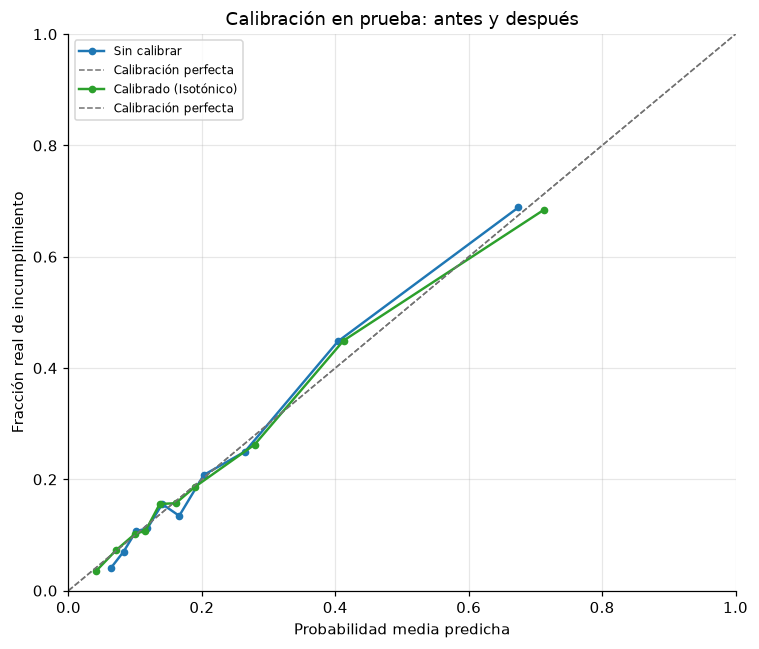

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
graficar_curva(
    ax,
    y_test,
    prob_sin_calibrar,
    "Sin calibrar",
    COLORES["sin_calibrar"],
)
graficar_curva(
    ax,
    y_test,
    prob_final,
    f"Calibrado ({ETIQUETAS_METODO[metodo_elegido]})",
    COLORES[metodo_elegido],
)
ax.set_title("Calibración en prueba: antes y después")
fig.tight_layout()
ruta_figura_global = RESULTADOS / "04_calibracion_global.png"
fig.savefig(ruta_figura_global, bbox_inches="tight")
plt.show()

En la figura global, la curva calibrada queda más cerca de la diagonal que la
curva sin calibrar, sobre todo en la zona baja y en el tramo medio. La mejora
no es perfecta: en algunos bins las dos curvas se cruzan o quedan casi
encima. Eso es consistente con la mejora modesta del ECE (`0.017198` a
`0.012525`) y con el hecho de que el modelo base ya tenía un AUC razonable.
La figura se guardó en `resultados/04_calibracion_global.png`.

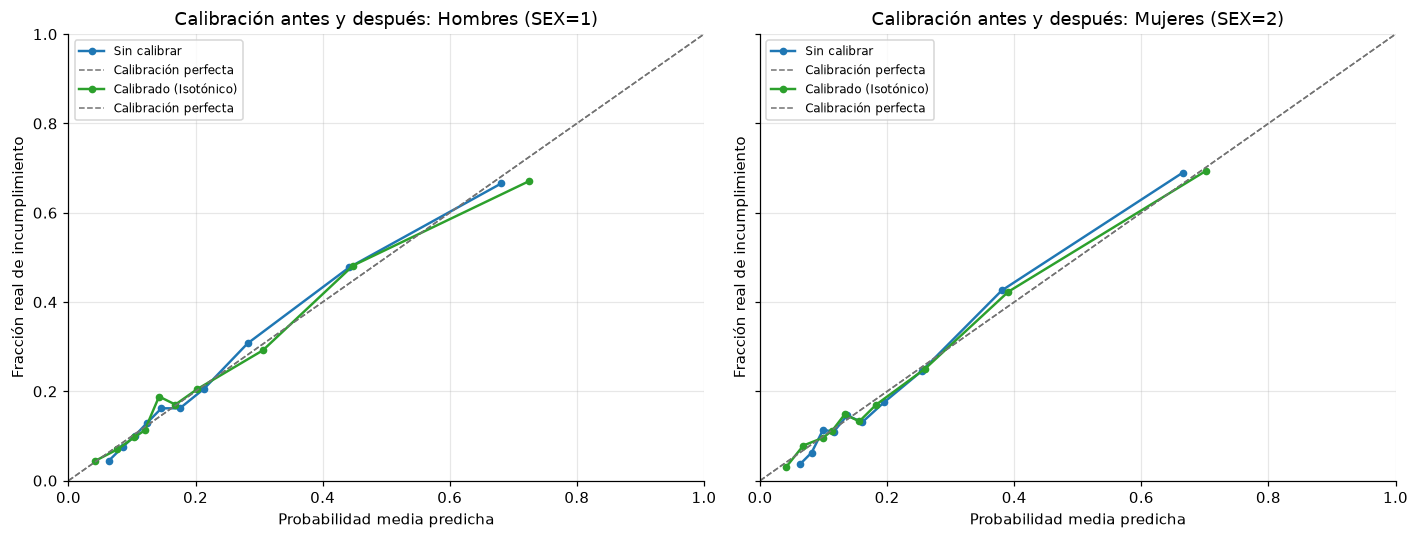

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (sexo_valor, nombre) in zip(
    axes,
    [(1, "Hombres (SEX=1)"), (2, "Mujeres (SEX=2)")],
):
    mascara = sexo_test == sexo_valor
    graficar_curva(
        ax,
        y_test[mascara],
        prob_sin_calibrar[mascara],
        "Sin calibrar",
        COLORES["sin_calibrar"],
    )
    graficar_curva(
        ax,
        y_test[mascara],
        prob_final[mascara],
        f"Calibrado ({ETIQUETAS_METODO[metodo_elegido]})",
        COLORES[metodo_elegido],
    )
    ax.set_title(f"Calibración antes y después: {nombre}")
fig.tight_layout()
ruta_figura_grupos = RESULTADOS / "04_calibracion_grupos.png"
fig.savefig(ruta_figura_grupos, bbox_inches="tight")
plt.show()

En las curvas por grupo se ve el mismo patrón que en la tabla: en mujeres la
curva calibrada se acerca más a la diagonal y el ECE baja; en hombres la
mejora no es uniforme y el ECE sube un poco. Esto no significa que el
calibrador esté mal: significa que un calibrador global no puede corregir de
forma óptima dos distribuciones distintas al mismo tiempo. La decisión de
no calibrar por grupo se registra en la bitácora (Decisión 4); aquí solo se
documenta la evidencia. La figura se guardó en `resultados/04_calibracion_grupos.png`.

## 7. Guardado de probabilidades calibradas

Se guardan las probabilidades de prueba de las tres versiones: sin calibrar,
sigmoide e isotónico. La columna `prob_calibrada` contiene la versión elegida
por la CV (isotónico). `SEX` se conserva solo para auditoría; no fue entrada
del modelo ni del calibrador.

In [13]:
tabla_probabilidades_calibradas = pd.DataFrame(
    {
        "indice": idx_test,
        "objetivo": y_test,
        "SEX": sexo_test,
        "prob_sin_calibrar": prob_sin_calibrar,
        "prob_sigmoide": probabilidades_calibradas["sigmoid"],
        "prob_isotonic": probabilidades_calibradas["isotonic"],
        "prob_calibrada": prob_final,
        "metodo_calibracion": metodo_elegido,
    }
)
display(tabla_probabilidades_calibradas.head(10).round(6))

ruta_probabilidades_calibradas = (
    RESULTADOS / "04_probabilidades_calibradas_test.csv"
)
tabla_probabilidades_calibradas.to_csv(
    ruta_probabilidades_calibradas,
    index=False,
    float_format="%.8f",
)

tabla_metodo = pd.DataFrame(
    [
        {
            "modelo_id": mejor["modelo_id"],
            "modelo": mejor["modelo"],
            "metodo_calibracion": metodo_elegido,
            "criterio": (
                "menor log-loss en validación cruzada anidada dentro del 70%"
            ),
            "auc_cv_medio_modelo": float(mejor["auc_cv_medio"]),
            "auc_test_sin_calibrar": float(mejor["auc_test"]),
        }
    ]
)
ruta_metodo = RESULTADOS / "04_metodo_calibracion.csv"
tabla_metodo.to_csv(ruta_metodo, index=False, float_format="%.8f")

print(f"Probabilidades guardadas en: {ruta_probabilidades_calibradas}")
print(f"Filas guardadas: {len(tabla_probabilidades_calibradas)}")
print(f"Columnas: {list(tabla_probabilidades_calibradas.columns)}")
print(f"Metadatos del método guardados en: {ruta_metodo}")

,indice,objetivo,SEX,prob_sin_calibrar,prob_sigmoide,prob_isotonic,prob_calibrada,metodo_calibracion
0,0,1,2,0.658245,0.668641,0.651840,0.651840,isotonic
1,1,1,2,0.352693,0.366691,0.352051,0.352051,isotonic
2,4,0,1,0.091103,0.087378,0.092283,0.092283,isotonic
3,5,0,1,0.159978,0.153270,0.153128,0.153128,isotonic
4,7,0,2,0.157503,0.169222,0.164470,0.164470,isotonic
5,9,0,1,0.186396,0.166585,0.165777,0.165777,isotonic
6,13,1,1,0.462646,0.483059,0.450015,0.450015,isotonic
7,19,0,2,0.300110,0.297410,0.325172,0.325172,isotonic
8,26,1,1,0.262971,0.247187,0.262095,0.262095,isotonic
9,34,0,1,0.067314,0.060571,0.050741,0.050741,isotonic


Probabilidades guardadas en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_probabilidades_calibradas_test.csv
Filas guardadas: 9000
Columnas: ['indice', 'objetivo', 'SEX', 'prob_sin_calibrar', 'prob_sigmoide', 'prob_isotonic', 'prob_calibrada', 'metodo_calibracion']
Metadatos del método guardados en: /home/tito/repos/RDP/Examen_1_RDP/resultados/04_metodo_calibracion.csv


La tabla mostrada son las primeras 10 de las 9,000 filas de prueba. El
archivo completo conserva el índice original, el objetivo, `SEX` y las
probabilidades de las tres versiones. `prob_calibrada` es la que debe usarse
en los siguientes incisos si se decide trabajar con el calibrador global
isotónico. `SEX` permite repetir la auditoría por grupo, pero no se usó para
predecir ni para calibrar.

## 8. Cierre del inciso (b)

- El mejor modelo se eligió por AUC de validación cruzada:
  `HistGradientBoostingClassifier` con `0.781596 ± 0.005092`.
- El modelo no estaba suficientemente calibrado: ECE global `0.017198` y ECE
  de mujeres `0.020334`, aunque las medias por grupo ya eran cercanas.
- Se compararon sigmoide e isotónico con validación cruzada anidada dentro
  del 70%; el isotónico tuvo el menor log-loss (`0.426337`).
- Se ajustó un único calibrador global isotónico con el 70% y `cv=5`; en
  prueba el ECE bajó a `0.012525`, el Brier a `0.135246` y el log-loss a
  `0.430305`.
- No se calibró por grupo (decisión registrada en la bitácora, Decisión 4).

Esta libreta no pasa al Problema 2.